# 02 · Cleaning & preprocessing

**Owner:** Aayush · **Phase 2** of the StayScope pipeline

This notebook turns the raw datasets into clean, model-ready data. The logic lives in
`src/churn/preprocessing.py`. This notebook runs it, explains every decision, and shows before/after evidence.

| Step | Dataset A (5K) | Dataset S (243K) |
|---|---|---|
| Duplicates, missing values, whitespace | checked | checked |
| Out-of-range values | checked | checked |
| Derived columns | drop `avg_watch_time_per_day` | drop `total_charges` |
| Redundant columns | drop `monthly_fee` | – |
| Yes/No columns | – | convert to 1/0 |
| Skewed columns | keep the `watch_hours` tail, log-transform for linear models | – |
| Encoding & scaling | inside the model pipeline (fitted on train only) | same |

Old dataset B was excluded in notebook 01 (no churn signal), so it is not cleaned.

**Outputs:** `data/interim/a_clean.csv`, `data/interim/s_clean.csv`, `reports/results/cleaning_log.csv`.
These files are gitignored. Anyone can regenerate them with `python -m churn.preprocessing`.

## 1. Setup

In [1]:
import warnings

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

from churn import config, data, eda, preprocessing as pp
from churn.plotting import CHURN, NEUTRAL, RETAINED, savefig, set_style

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
set_style()
config.ensure_dirs()
TARGET, ID = config.TARGET, config.ID_COL

raw_a = data.load_a()
raw_s = data.load_s()
print(f"Raw A: {raw_a.shape} · Raw S: {raw_s.shape}")

Raw A: (5000, 14) · Raw S: (243787, 21)


## 2. Run the cleaning pipeline

In [2]:
a, log_a = pp.clean_a(raw_a)
s, log_s = pp.clean_s(raw_s)
log = pd.concat([log_a, log_s], ignore_index=True)
log

,dataset,step,rows_before,rows_after,cols_before,cols_after,n_affected,note
0,A,Trim whitespace in text columns,5000,5000,14,14,0,Normalise category labels
1,A,Remove duplicate customer IDs,5000,5000,14,14,0,Keep the first record per ID
2,A,Remove duplicate rows (ignoring ID),5000,5000,14,14,0,Identical records
3,A,Drop rows with missing values,5000,5000,14,14,0,No imputation needed: both datasets are complete
4,A,Drop rows with out-of-range values,5000,5000,14,14,0,"Checked: age, watch_hours, last_login_days, number_of_profiles"
5,A,Drop avg_watch_time_per_day,5000,5000,14,13,10,Derived: watch_hours / (last_login_days + 1); 10 rows were > 24 h/day
6,A,Drop monthly_fee,5000,5000,13,12,0,Redundant: one fixed fee per subscription_type
7,A,Keep watch_hours outliers,5000,5000,12,12,238,Plausible heavy viewers; log1p-transformed for Logistic Regression
8,S,Trim whitespace in text columns,243787,243787,21,21,0,Normalise category labels
9,S,Remove duplicate customer IDs,243787,243787,21,21,0,Keep the first record per ID


Both datasets keep **every row**: there are no duplicates, missing values or out-of-range values to remove.
Cleaning here means **removing columns that would mislead the models** and **fixing data types**. The
sections below justify each change.

## 3. Dataset A

### 3.1 `avg_watch_time_per_day`: derived and partly invalid → dropped

Notebook 01 showed that this column is exactly `watch_hours / (last_login_days + 1)`. We considered three options:

| Option | Problem |
|---|---|
| Keep as-is | 10 impossible values (> 24 h/day); also double-counts two columns the model already has |
| Cap at 24 h/day | Removes the impossible values, but the column is still a ratio of existing columns |
| **Drop** ✔ | Tree models can learn the interaction from `watch_hours` and `last_login_days` directly |

All 10 invalid rows come from customers who logged in **today** (`last_login_days` = 0 or 1). The formula then
treats their whole `watch_hours` as a single day:

Invalid rows: 10 · last_login_days values among them: [np.int64(0), np.int64(1)]


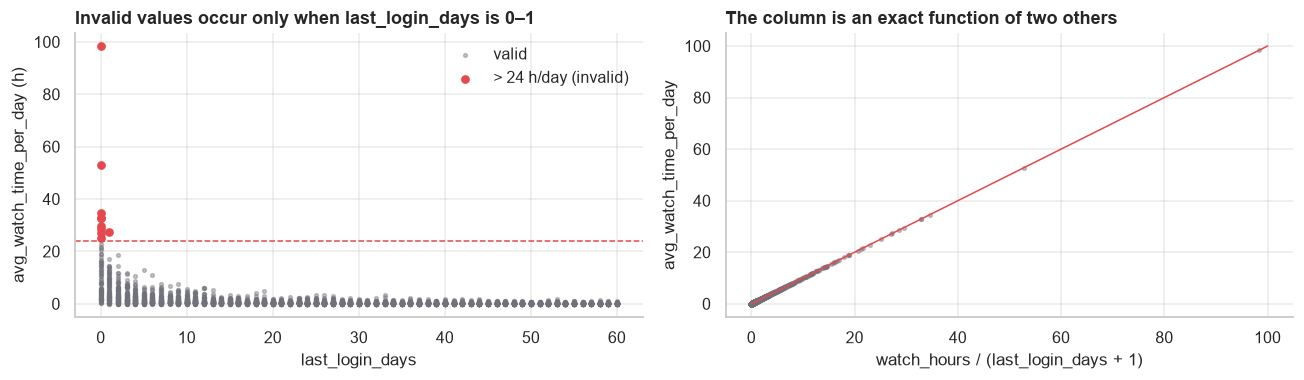

In [3]:
bad = raw_a[raw_a["avg_watch_time_per_day"] > 24]
print(f"Invalid rows: {len(bad)} · last_login_days values among them: {sorted(bad['last_login_days'].unique())}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
ax = axes[0]
ok = raw_a["avg_watch_time_per_day"] <= 24
ax.scatter(raw_a.loc[ok, "last_login_days"], raw_a.loc[ok, "avg_watch_time_per_day"], s=6, color=NEUTRAL, alpha=0.4,
           label="valid")
ax.scatter(bad["last_login_days"], bad["avg_watch_time_per_day"], s=22, color=CHURN, label="> 24 h/day (invalid)")
ax.axhline(24, color=CHURN, ls="--", lw=1)
ax.set_xlabel("last_login_days")
ax.set_ylabel("avg_watch_time_per_day (h)")
ax.set_title("Invalid values occur only when last_login_days is 0–1")
ax.legend()
ax = axes[1]
recon = raw_a["watch_hours"] / (raw_a["last_login_days"] + 1)
ax.scatter(recon, raw_a["avg_watch_time_per_day"], s=6, color=NEUTRAL, alpha=0.4)
ax.plot([0, 100], [0, 100], color=CHURN, lw=1)
ax.set_xlabel("watch_hours / (last_login_days + 1)")
ax.set_ylabel("avg_watch_time_per_day")
ax.set_title("The column is an exact function of two others")
fig.tight_layout()
savefig(fig, "02_a_avg_watch_time_dropped")
plt.show()

### 3.2 `monthly_fee`: redundant → dropped
There is one fixed fee per plan (Basic 8.99, Standard 13.99, Premium 17.99), so `monthly_fee` carries exactly the
same information as `subscription_type`. We keep `subscription_type` because it is also a shared column with
Dataset S (needed for matching in notebook 04).

In [4]:
pd.crosstab(raw_a["subscription_type"], raw_a["monthly_fee"])

monthly_fee,8.990,13.990,17.990
subscription_type,,,
Basic,1661,0,0
Premium,0,0,1693
Standard,0,1646,0


### 3.3 `watch_hours`: long tail → kept, log-transformed for linear models
238 customers (4.8%) are IQR outliers, with up to 110 hours. These are plausible heavy viewers, not errors, and
they are informative (heavy viewers rarely churn). Deleting them would bias the data. Trees don't care about
skew. For **Logistic Regression**, `make_preprocessor(..., log_cols=["watch_hours"])` applies `log1p` before
scaling, which makes the distribution far more symmetric:

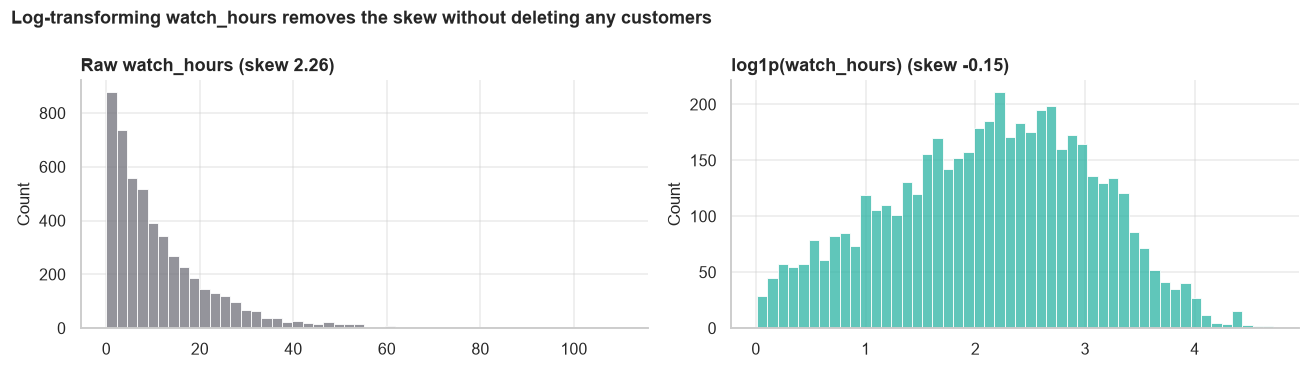

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
sns.histplot(a["watch_hours"], bins=50, color=NEUTRAL, ax=axes[0])
axes[0].set_title(f"Raw watch_hours (skew {a['watch_hours'].skew():.2f})")
sns.histplot(np.log1p(a["watch_hours"]), bins=50, color=RETAINED, ax=axes[1])
axes[1].set_title(f"log1p(watch_hours) (skew {np.log1p(a['watch_hours']).skew():.2f})")
for ax in axes:
    ax.set_xlabel("")
fig.suptitle("Log-transforming watch_hours removes the skew without deleting any customers",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
savefig(fig, "02_a_watch_hours_log")
plt.show()

## 4. Dataset S

### 4.1 `total_charges`: derived → dropped
`total_charges` equals `account_age × monthly_charges` for **every** customer. Keeping it would let a model
"see" tenure and price twice, which inflates their apparent importance in SHAP and feature-importance plots.

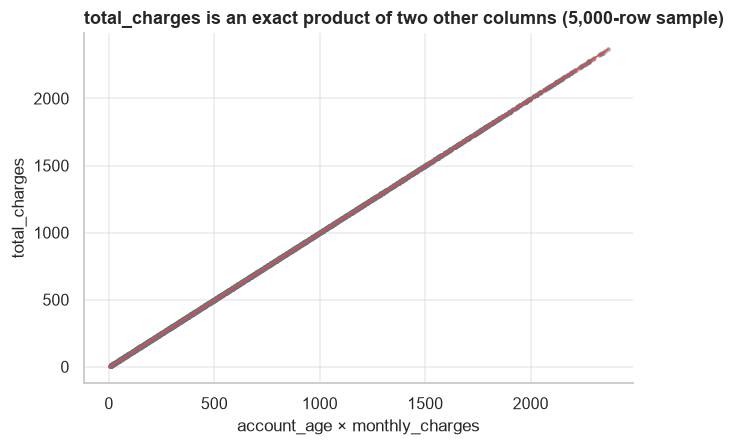

Max absolute difference over all rows: 0.0


In [6]:
sample = raw_s.sample(5000, random_state=config.RANDOM_STATE)
fig, ax = plt.subplots(figsize=(6, 4.2))
ax.scatter(sample["account_age"] * sample["monthly_charges"], sample["total_charges"], s=5, color=NEUTRAL, alpha=0.4)
lim = sample["total_charges"].max()
ax.plot([0, lim], [0, lim], color=CHURN, lw=1)
ax.set_xlabel("account_age × monthly_charges")
ax.set_ylabel("total_charges")
ax.set_title("total_charges is an exact product of two other columns (5,000-row sample)")
fig.tight_layout()
savefig(fig, "02_s_total_charges_dropped")
plt.show()
print("Max absolute difference over all rows:",
      (raw_s["total_charges"] - raw_s["account_age"] * raw_s["monthly_charges"]).abs().max())

### 4.2 Yes/No columns → 1/0

In [7]:
pd.DataFrame({c: {"raw 'Yes' count": int((raw_s[c] == "Yes").sum()), "clean sum of 1s": int(s[c].sum()),
                  "clean dtype": str(s[c].dtype)} for c in pp.S_FEATURES_BINARY}).T

,raw 'Yes' count,clean sum of 1s,clean dtype
paperless_billing,121807,121807,int64
multi_device_access,121752,121752,int64
parental_control,122085,122085,int64
subtitles_enabled,122180,122180,int64


The counts match exactly, so the conversion lost nothing. These four columns are then passed to the models
unchanged (they are already 0/1).

## 5. Before vs after

In [8]:
summary = pd.DataFrame({
    "rows (raw)": [len(raw_a), len(raw_s)], "rows (clean)": [len(a), len(s)],
    "columns (raw)": [raw_a.shape[1], raw_s.shape[1]], "columns (clean)": [a.shape[1], s.shape[1]],
    "churn rate": [a[TARGET].mean(), s[TARGET].mean()],
}, index=["A", "S"])
summary

,rows (raw),rows (clean),columns (raw),columns (clean),churn rate
A,5000,5000,14,12,0.503
S,243787,243787,21,20,0.181


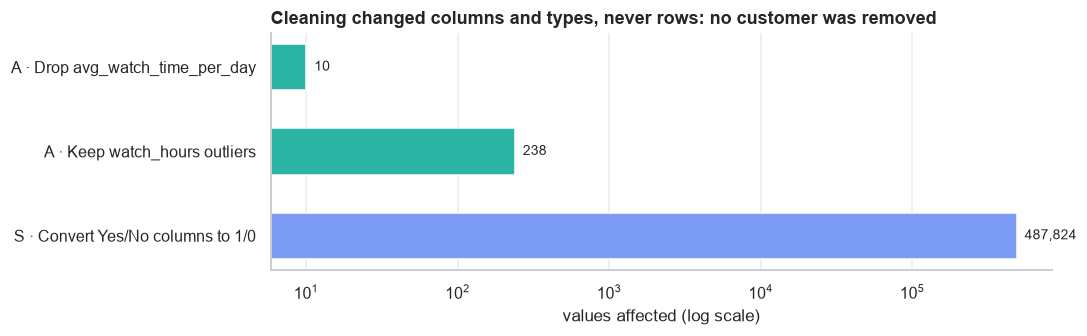

In [9]:
fig, ax = plt.subplots(figsize=(10, 3.2))
steps = log[log["n_affected"] > 0].copy()
steps["label"] = steps["dataset"] + " · " + steps["step"]
ax.barh(steps["label"], steps["n_affected"], color=[RETAINED if d == "A" else "#7C9CF5" for d in steps["dataset"]],
        height=0.55)
for y, v in enumerate(steps["n_affected"]):
    ax.text(v, y, f"  {v:,}", va="center", fontsize=9)
ax.set_xscale("log")
ax.set_xlabel("values affected (log scale)")
ax.set_title("Cleaning changed columns and types, never rows: no customer was removed")
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
fig.tight_layout()
savefig(fig, "02_cleaning_log")
plt.show()

In [10]:
print("Clean A")
display(eda.schema_summary(a))
print("Clean S")
display(eda.schema_summary(s))

Clean A


,column,dtype,kind,unique,missing,missing_pct,example
0,customer_id,str,categorical,5000,0,0.000,a9b75100-82a8-427a-a208-72f24052884a
1,age,int64,numeric,53,0,0.000,51
2,gender,str,categorical,3,0,0.000,Other
3,subscription_type,str,categorical,3,0,0.000,Basic
4,watch_hours,float64,numeric,2343,0,0.000,14.730
5,last_login_days,int64,numeric,61,0,0.000,29
6,region,str,categorical,6,0,0.000,Africa
7,device,str,categorical,5,0,0.000,TV
8,churned,int64,numeric,2,0,0.000,1
9,payment_method,str,categorical,5,0,0.000,Gift Card


Clean S


,column,dtype,kind,unique,missing,missing_pct,example
0,customer_id,str,categorical,243787,0,0.000,CB6SXPNVZA
1,account_age,int64,numeric,119,0,0.000,20
2,monthly_charges,float64,numeric,243787,0,0.000,11.055
3,subscription_type,str,categorical,3,0,0.000,Premium
4,payment_method,str,categorical,4,0,0.000,Mailed check
5,paperless_billing,int64,numeric,2,0,0.000,0
6,content_type,str,categorical,3,0,0.000,Both
7,multi_device_access,int64,numeric,2,0,0.000,0
8,device,str,categorical,4,0,0.000,Mobile
9,viewing_hours_per_week,float64,numeric,243787,0,0.000,36.758


## 6. Encoding & scaling: the model-ready transformer

The report's preprocessing also includes **encoding categorical variables and normalizing numeric ones**. That
is done by `pp.make_preprocessor`, which builds an sklearn `ColumnTransformer`:

* numeric → (optional `log1p`) → `StandardScaler`
* categorical → `OneHotEncoder(handle_unknown="ignore")`
* binary 0/1 → passed through

It is **not** applied to the saved CSVs. It goes *inside* each model's `Pipeline` in notebook 05, so it is
**fitted on the training split only**. Fitting the scaler on all the data would leak information about the
test set into training. The demo below fits on a 70% training split and then transforms the remaining 30%.

In [11]:
from sklearn.model_selection import train_test_split

train_s, test_s = train_test_split(s, test_size=0.30, stratify=s[TARGET], random_state=config.RANDOM_STATE)
prep_s = pp.make_preprocessor(pp.S_FEATURES_NUMERIC, pp.S_FEATURES_CATEGORICAL, binary=pp.S_FEATURES_BINARY)
Xtr = prep_s.fit_transform(train_s)
Xte = prep_s.transform(test_s)
print(f"S: {len(pp.S_FEATURES_NUMERIC)} numeric + {len(pp.S_FEATURES_CATEGORICAL)} categorical "
      f"+ {len(pp.S_FEATURES_BINARY)} binary columns -> {Xtr.shape[1]} model features")
Xtr.head()

S: 8 numeric + 6 categorical + 4 binary columns -> 33 model features


,account_age,monthly_charges,viewing_hours_per_week,avg_viewing_duration,content_downloads_per_month,user_rating,support_tickets_per_month,watchlist_size,subscription_type_Basic,subscription_type_Premium,subscription_type_Standard,payment_method_Bank transfer,payment_method_Credit card,payment_method_Electronic check,payment_method_Mailed check,content_type_Both,content_type_Movies,content_type_TV Shows,device_Computer,device_Mobile,device_TV,device_Tablet,favorite_genre_Action,favorite_genre_Comedy,favorite_genre_Drama,favorite_genre_Fantasy,favorite_genre_Sci-Fi,gender_Female,gender_Male,paperless_billing,multi_device_access,parental_control,subtitles_enabled
144950,0.146,1.691,0.284,1.684,-0.104,0.146,0.173,-1.534,0.000,0.000,1.000,0.000,1.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,1.000,0.000,1.000,0.000,0.000,0.000,0.000,1.000,0,1,1,1
158811,-1.311,0.642,0.884,-0.231,-1.074,0.981,-0.525,-0.839,1.000,0.000,0.000,1.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,1.000,0,1,0,0
185002,-0.670,-0.523,-0.256,-0.829,0.035,-0.273,1.567,-0.561,0.000,1.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,1.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,1.000,0.000,1.000,0.000,1,0,1,0
211124,-1.049,-0.579,1.399,-0.272,0.451,1.121,0.521,1.248,1.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,1.000,0.000,1.000,0.000,0.000,0.000,0.000,1.000,0.000,0,1,1,1
153715,-1.515,-0.826,0.025,0.556,-0.935,-0.399,1.219,0.830,1.000,0.000,0.000,1.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,1.000,0.000,0,1,1,0


In [12]:
check = pd.DataFrame({
    "train mean": Xtr[pp.S_FEATURES_NUMERIC].mean(), "train std": Xtr[pp.S_FEATURES_NUMERIC].std(),
    "test mean": Xte[pp.S_FEATURES_NUMERIC].mean(), "test std": Xte[pp.S_FEATURES_NUMERIC].std(),
})
check

,train mean,train std,test mean,test std
account_age,-0.000,1.000,0.010,0.998
monthly_charges,0.000,1.000,-0.002,1.001
viewing_hours_per_week,-0.000,1.000,-0.012,1.001
avg_viewing_duration,-0.000,1.000,-0.000,1.000
content_downloads_per_month,0.000,1.000,0.002,0.999
user_rating,0.000,1.000,-0.005,0.999
support_tickets_per_month,0.000,1.000,-0.001,1.005
watchlist_size,0.000,1.000,-0.005,1.001


The training columns have a mean of exactly 0 and a standard deviation of 1. The test columns are close but not
exact, because they were scaled with the **training** statistics. That is the expected, leakage-free behaviour.

In [13]:
prep_a = pp.make_preprocessor(pp.A_FEATURES_NUMERIC, pp.A_FEATURES_CATEGORICAL, log_cols=pp.A_LOG_COLS)
Xa = prep_a.fit_transform(a)
print(f"A: {len(pp.A_FEATURES_NUMERIC)} numeric + {len(pp.A_FEATURES_CATEGORICAL)} categorical columns "
      f"-> {Xa.shape[1]} model features")
print("Feature names:", list(Xa.columns))

A: 4 numeric + 6 categorical columns -> 33 model features
Feature names: ['watch_hours', 'age', 'last_login_days', 'number_of_profiles', 'gender_Female', 'gender_Male', 'gender_Other', 'subscription_type_Basic', 'subscription_type_Premium', 'subscription_type_Standard', 'region_Africa', 'region_Asia', 'region_Europe', 'region_North America', 'region_Oceania', 'region_South America', 'device_Desktop', 'device_Laptop', 'device_Mobile', 'device_TV', 'device_Tablet', 'payment_method_Credit Card', 'payment_method_Crypto', 'payment_method_Debit Card', 'payment_method_Gift Card', 'payment_method_PayPal', 'favorite_genre_Action', 'favorite_genre_Comedy', 'favorite_genre_Documentary', 'favorite_genre_Drama', 'favorite_genre_Horror', 'favorite_genre_Romance', 'favorite_genre_Sci-Fi']


## 7. Save

In [14]:
out = pp.run()   # same functions as above; writes the files
for path in [config.CLEAN_A, config.CLEAN_S, config.RESULTS_DIR / "cleaning_log.csv"]:
    print(f"{path.relative_to(config.ROOT)}  ({path.stat().st_size / 1e6:.1f} MB)")
assert out["a"].equals(a) and out["s"].equals(s)

data\interim\a_clean.csv  (0.5 MB)
data\interim\s_clean.csv  (37.7 MB)
reports\results\cleaning_log.csv  (0.0 MB)


## 8. Summary and handoff

* **No rows were removed.** Both datasets were already complete, duplicate-free and within valid ranges.
* **Columns removed:** A `avg_watch_time_per_day` (derived, 10 invalid values) and `monthly_fee` (redundant);
  S `total_charges` (derived).
* **Types fixed:** S's four Yes/No columns are now 1/0.
* **Kept on purpose:** A's heavy `watch_hours` viewers, log-transformed only for linear models.
* **Encoding & scaling** is handled by `pp.make_preprocessor` inside each model pipeline (notebook 05).

**For Sukhraj (notebooks 03–04):** load the clean data with `data.load_clean_a()` and `data.load_clean_s()`.
If the files are missing, run `python -m churn.preprocessing` first. The shared columns (`subscription_type`,
`device`, `favorite_genre`, `payment_method`, `gender`) already have identical names in both datasets.
To build `A_hard`, drop `watch_hours` and `last_login_days` (`avg_watch_time_per_day` is already gone).